# Cross-Validation and GridSearchCV with Scikit-learn

A worked example of model evaluation and tuning on the Breast Cancer Wisconsin dataset, using a protocol that avoids the usual leaks:

1. Hold out a stratified **test set first** and never use it for any decision.
2. Do all cross-validation, tuning and model comparison on the **training set only**.
3. Put scaling inside a `Pipeline` so it is re-fitted on each training fold.
4. Report cross-validated scores as mean ± std, compared against a majority-class baseline.
5. Estimate the effect of tuning itself with **nested cross-validation**.
6. Evaluate the single chosen model on the test set **once**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import (GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_val_score, train_test_split, validation_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

sns.set_theme(style="whitegrid")

In this notebook, we will cover:

- What is Cross-Validation?
- Why is it needed in classification?
- k-Fold Cross-Validation explained
- Using `cross_val_score` for classification
- What is GridSearchCV?
- How to use GridSearchCV with Logistic Regression and Decision Tree Classifier

We'll use the **Breast Cancer Wisconsin Dataset** for classification tasks.

## Load and Inspect Dataset

We'll load the Breast Cancer dataset and convert it into a pandas DataFrame.

In [2]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name='Cancer')  # 0 = malignant, 1 = benign

In [3]:
X.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## Train-Test Split
An 80/20 **stratified** split. From here on, `X_test`/`y_test` are left alone until the very last section; everything else uses `X_train`/`y_train`.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"train: {len(X_train)} rows, test: {len(X_test)} rows, malignant share train/test: "
      f"{(y_train == 0).mean():.3f} / {(y_test == 0).mean():.3f}")

train: 455 rows, test: 114 rows, malignant share train/test: 0.374 / 0.368


# Cross-Validation in Classification

Cross-validation splits the data into multiple training/validation sets to evaluate model performance more reliably than a single split.

## k-Fold Cross-Validation (k=5):

- Split data into 5 equal parts (folds)
- Train on 4 folds, validate on 1
- Repeat for all folds and average the performance

## Models and cross-validation scheme

Logistic regression is scale-sensitive, so it gets a `StandardScaler` inside a pipeline. Trees do not need scaling. Cross-validation is **repeated stratified 5-fold** (5 repeats = 25 fits), so the spread of the score is visible, not just its mean.

In [5]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=0)

models = {
    'majority baseline': DummyClassifier(strategy='most_frequent'),
    'logistic regression (unscaled)': LogisticRegression(max_iter=10000, solver='liblinear'),
    'logistic regression (scaled)': Pipeline([('scale', StandardScaler()), ('clf', LogisticRegression(max_iter=10000))]),
    'decision tree (default)': DecisionTreeClassifier(random_state=42),
}
rows = []
for name, m in models.items():
    s = cross_val_score(m, X_train, y_train, cv=cv, scoring='accuracy')
    rows.append((name, s.mean(), s.std(), s.min(), s.max()))
cv_table = pd.DataFrame(rows, columns=['model', 'mean_acc', 'std', 'min', 'max']).set_index('model')
cv_table.round(3)

,mean_acc,std,min,max
model,,,,
majority baseline,0.626,0.000,0.626,0.626
logistic regression (unscaled),0.948,0.017,0.923,0.978
logistic regression (scaled),0.980,0.011,0.956,1.000
decision tree (default),0.929,0.016,0.901,0.956


**Reading the table.** Every model must clear the ~63 % majority baseline. Scaling matters for logistic regression, and the spread (`std`, `min`-`max` over 25 folds) shows how much a single 5-fold number can move by chance. The test rows never enter any of these numbers.

# GridSearchCV for Hyperparameter Tuning


## Understanding the Complete GridSearchCV Process

`GridSearchCV` is a powerful model selection tool provided by `sklearn` to help find the **best hyperparameters** for a given model using **cross-validation**.

Here is how the entire process works:

---

### Step-by-Step Working of GridSearchCV

1. **Define the Model**  
   You start by choosing an estimator (e.g., `DecisionTreeClassifier`, `LogisticRegression`, etc.).

2. **Create a Parameter Grid**  
   You specify a dictionary of hyperparameters to test.  
   Example:
   ```python
   param_grid = {
       'max_depth': [3, 5, 10],
       'criterion': ['gini', 'entropy']
   }
   ```

3. **Initialize GridSearchCV**  
   You pass the estimator and parameter grid to `GridSearchCV`, and define:
   - `cv`: Number of folds in cross-validation
   - `scoring`: Evaluation metric (e.g., `'accuracy'`, `'f1'`, `'neg_mean_squared_error'`)
   - `n_jobs=-1`: Use all available CPU cores for faster computation

   Example:
   ```python
   grid = GridSearchCV(estimator, param_grid, cv=5, scoring='accuracy')
   ```

4. **Fit on Training Data**  
   When you call `grid.fit(X_train, y_train)`, GridSearchCV:
   - Iterates through **all combinations** of hyperparameters
   - For **each combination**:
     - Performs **k-fold cross-validation** (e.g., 5-fold)
     - Calculates the **average performance score**
   - Keeps track of the **best-performing hyperparameter combination**

5. **Retrieve Best Model & Parameters**  
   After fitting:
   - `grid.best_params_` → Shows the best hyperparameters found
   - `grid.best_score_` → Shows the best cross-validated score
   - `grid.best_estimator_` → Returns the final model trained with the best parameters on the **entire training set**

---

### Why Use GridSearchCV?

- Avoids manual trial-and-error of hyperparameters.
- Ensures fair evaluation using cross-validation.
- Helps find a model that **generalizes better** to unseen data.
- Works with **any estimator** in `sklearn`.

---

### Summary of Key Attributes

| Attribute | Description |
|-----------|-------------|
| `best_params_` | Dictionary of the best hyperparameter combination |
| `best_score_`  | Best cross-validation score achieved |
| `best_estimator_` | Trained model with best hyperparameters |
| `cv_results_` | Full history of all parameter combinations and their scores |

---

GridSearchCV is especially useful in combination with **pipelines**, **scaling**, and **preprocessing**, and it can be used for both **classification** and **regression** problems.


GridSearchCV allows us to find the best combination of hyperparameters through exhaustive search.

We'll use it to tune:
- Decision Tree Classifier (`max_depth`, `min_samples_split`, `criterion`)

## Decision Tree Grid Search (Explanation)



We’ll search over:
- `max_depth`: How deep the tree can go
- `min_samples_split`: Minimum samples to split a node
- `criterion`: Splitting strategy ('gini', 'entropy')

### 1. What is `param_grid_dt`?

This dictionary defines the hyperparameters and their values to be explored during grid search:

- `'max_depth'`: Maximum depth of the tree.
    - `[3, 5, 10, None]`: Tests shallow, medium, deep, and unlimited depth trees.
- `'min_samples_split'`: Minimum samples required to split an internal node.
    - `[2, 5, 10]`: Larger values make trees less complex.
- `'criterion'`: Function used to measure the quality of a split.
    - `['gini', 'entropy']`: Two standard methods — Gini Impurity and Entropy (Information Gain).

This creates **4 × 3 × 2 = 24 different combinations** to try.

---

### 2. What does `GridSearchCV(...)` do?

- `DecisionTreeClassifier(random_state=42)`: The base estimator we want to tune.
- `param_grid=param_grid_dt`: The hyperparameter space to search.
- `cv=5`: Perform **5-fold Cross-Validation**:
    - For each parameter combination, the model is trained/validated across 5 different splits of the training data.
- `scoring='accuracy'`: Uses **classification accuracy** to score performance.
- `n_jobs=-1`: Use **all CPU cores** to parallelize computation.

This means the model will be trained **24 × 5 = 120 times** during the search.

---

### 3. What happens during `grid_dt.fit(X_train, y_train)`?

When `.fit()` is called:

1. GridSearch tries all 24 combinations of parameters.
2. For each combination:
    - It performs **5-fold cross-validation**.
    - Calculates the **average accuracy** across the 5 folds.
3. Tracks the combination with the highest average accuracy.

---

### 4. What do `best_params_` and `best_score_` show?

- `grid_dt.best_params_`:
    - Returns the **best hyperparameter combination** found during search.
- `grid_dt.best_score_`:
    - The **highest average accuracy** achieved across 5-folds using those best parameters.

---

### Grid search for the decision tree (training data only)

In [6]:
param_grid_dt = {
    'max_depth': [3, 5, 10, None],
    'min_samples_split': [2, 5, 10],
    'criterion': ['gini', 'entropy']
}

inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_dt = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid_dt, cv=inner_cv, scoring='accuracy', n_jobs=-1)
grid_dt.fit(X_train, y_train)

print("Best Parameters (DT):", grid_dt.best_params_)
print(f"Best CV Accuracy (DT, train only): {grid_dt.best_score_:.4f}")

Best Parameters (DT): {'criterion': 'entropy', 'max_depth': 3, 'min_samples_split': 2}
Best CV Accuracy (DT, train only): 0.9341


### Grid search for the logistic regression

The pipeline's step names are used as prefixes (`clf__C`). `C` is the inverse regularisation strength.

In [7]:
pipe_lr = Pipeline([('scale', StandardScaler()), ('clf', LogisticRegression(max_iter=10000))])
param_grid_lr = {'clf__C': [0.01, 0.1, 1, 10, 100]}

grid_lr = GridSearchCV(pipe_lr, param_grid_lr, cv=inner_cv, scoring='accuracy', n_jobs=-1)
grid_lr.fit(X_train, y_train)

print("Best Parameters (LR):", grid_lr.best_params_)
print(f"Best CV Accuracy (LR, train only): {grid_lr.best_score_:.4f}")

Best Parameters (LR): {'clf__C': 0.1}
Best CV Accuracy (LR, train only): 0.9824


## Nested cross-validation: how optimistic is `best_score_`?

`best_score_` is the maximum over many candidates, scored on the same folds that picked it, so it is optimistically biased. Nested CV wraps the *entire* grid search in an outer loop: each outer fold tunes on its own training part and is scored on data the tuning never saw.

In [8]:
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)
nested = {
    'decision tree': cross_val_score(GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid_dt, cv=inner_cv, n_jobs=-1),
                                     X_train, y_train, cv=outer_cv),
    'logistic regression': cross_val_score(GridSearchCV(pipe_lr, param_grid_lr, cv=inner_cv, n_jobs=-1),
                                           X_train, y_train, cv=outer_cv),
}
pd.DataFrame({
    'tuned best_score_ (inner CV)': [grid_dt.best_score_, grid_lr.best_score_],
    'nested CV mean': [v.mean() for v in nested.values()],
    'nested CV std': [v.std() for v in nested.values()],
}, index=nested.keys()).round(4)

,tuned best_score_ (inner CV),nested CV mean,nested CV std
decision tree,0.9341,0.9121,0.0120
logistic regression,0.9824,0.9780,0.0184


## Final test-set evaluation (once)

The tuned logistic regression and decision tree are each evaluated a single time on the held-out 20 %. No further tuning happens after looking at these numbers.

In [9]:
final = {'majority baseline': DummyClassifier(strategy='most_frequent').fit(X_train, y_train),
         'decision tree (tuned)': grid_dt.best_estimator_,
         'logistic regression (tuned)': grid_lr.best_estimator_}
print(pd.Series({k: accuracy_score(y_test, m.predict(X_test)) for k, m in final.items()}, name='test accuracy').round(4))

best_lr = grid_lr.best_estimator_
y_pred_lr = best_lr.predict(X_test)
print("\n", classification_report(y_test, y_pred_lr, target_names=data.target_names))
print("Confusion matrix (tuned logistic regression):\n", confusion_matrix(y_test, y_pred_lr))

majority baseline              0.6316
decision tree (tuned)          0.9474
logistic regression (tuned)    0.9737
Name: test accuracy, dtype: float64

               precision    recall  f1-score   support

   malignant       0.98      0.95      0.96        42
      benign       0.97      0.99      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114

Confusion matrix (tuned logistic regression):
 [[40  2]
 [ 1 71]]


## Effect of tree depth

Cross-validated accuracy against depth, on the **training set only**, with a ±1 std band. Training accuracy is shown alongside to expose over-fitting.

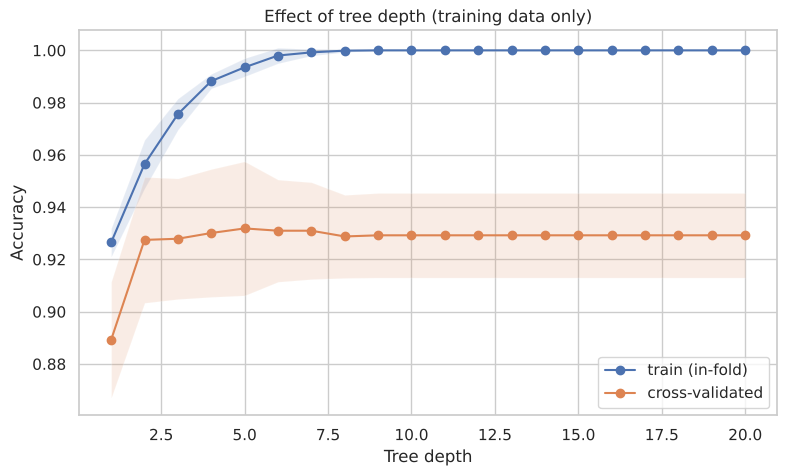

In [10]:
depths = np.arange(1, 21)
train_s, val_s = validation_curve(DecisionTreeClassifier(random_state=42), X_train, y_train,
                                  param_name='max_depth', param_range=depths, cv=cv, scoring='accuracy', n_jobs=-1)

fig, ax = plt.subplots(figsize=(9, 5))
for scores, label in [(train_s, 'train (in-fold)'), (val_s, 'cross-validated')]:
    ax.plot(depths, scores.mean(axis=1), marker='o', label=label)
    ax.fill_between(depths, scores.mean(axis=1) - scores.std(axis=1), scores.mean(axis=1) + scores.std(axis=1), alpha=0.15)
ax.set_xlabel("Tree depth"); ax.set_ylabel("Accuracy"); ax.set_title("Effect of tree depth (training data only)")
ax.legend(); plt.show()

## Summary and methodology notes

- Cross-validation estimates generalisation only if the data it sees excludes the final test set; tuning must happen inside the training data.
- A single 5-fold run is a noisy number; repeating the folds and reporting mean ± std is cheap on small data.
- `GridSearchCV.best_score_` is optimistic; nested CV shows by how much (typically small on this easy dataset, larger on harder or smaller problems).
- Scaling belongs in a `Pipeline`, otherwise validation folds leak their statistics into the scaler.
- The breast-cancer data is easy and well separated; differences of a fraction of a percentage point between tuned models are within noise.